# 04 · Business analysis
Descriptive KPIs from the canonical `historical_feature_outcome` table (no feature/outcome logic rebuilt here).
**Causal caveat:** `business_rule` offers were targeted, so raw offer comparisons are associations, not effects.
Incremental NCM is reported **only** from randomized `exploration` rows (difference in means vs NO_OFFER, 95% CI).

## Load data + KPI definitions

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from src.common import TABLES, FIGS, OFFERS, load_processed
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
df = load_processed("historical_feature_outcome")
df["is_offer"] = df.offer_type.ne("NO_OFFER").astype(int)
COLORS = dict(zip(OFFERS, ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]))
INK, MUTED = "#0b0b0b", "#898781"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": MUTED,
                     "axes.grid": True, "axes.axisbelow": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6,
                     "xtick.color": MUTED, "ytick.color": MUTED, "axes.labelcolor": INK, "font.size": 9})
print(df.shape)

(26600, 70)


In [2]:
def kpis(d, by):
    g = d.groupby(by, observed=True)
    k = g.agg(assignments=("assignment_id", "size"), conversion=("purchase_14d", "mean"), orders=("order_count_14d", "sum"),
              net_revenue=("net_revenue_14d", "sum"), offered=("is_offer", "sum"), redeemed=("offer_redeemed_14d", "sum"),
              promo_spend=("promo_cost_14d", "sum"), ncm_total=("ncm_14d", "sum"), ncm_per_assignment=("ncm_14d", "mean"),
              ncm_all_returns_per_assignment=("ncm_14d_all_returns", "mean"))
    k["aov"] = k.net_revenue / k.orders.where(k.orders > 0)
    k["redemption_rate"] = k.redeemed / k.offered.where(k.offered > 0)
    k["promo_spend_per_assignment"] = k.promo_spend / k.assignments
    return k[["assignments", "conversion", "aov", "redemption_rate", "promo_spend", "promo_spend_per_assignment", "ncm_total",
              "ncm_per_assignment", "ncm_all_returns_per_assignment"]].round(3)

def incremental(d, by=None):
    """Exploration-only difference in mean NCM vs NO_OFFER within each group (randomized → unbiased estimate)."""
    rows = []
    for key, s in (d.groupby(by, observed=True) if by else [("all", d)]):
        base = s[s.offer_type == "NO_OFFER"]
        for o in OFFERS[1:]:
            tr = s[s.offer_type == o]
            for y in ["ncm_14d", "ncm_14d_all_returns"]:
                diff = tr[y].mean() - base[y].mean()
                se = np.sqrt(tr[y].var() / len(tr) + base[y].var() / len(base))
                rows.append({"segment": key, "offer_type": o, "outcome": y, "n_treat": len(tr), "n_control": len(base),
                             "incremental_ncm": diff, "ci_low": diff - 1.96 * se, "ci_high": diff + 1.96 * se,
                             "incremental_conversion": tr.purchase_14d.mean() - base.purchase_14d.mean()})
    return pd.DataFrame(rows).round(3)
exp = df[df.assignment_source == "exploration"]

## Overall KPIs
Conversion = share of assignments with ≥1 eligible completed order in 14d · AOV = net revenue / orders ·
Redemption = redeemed offers / offered assignments · Promo spend = realized discount + inferred waived shipping ·
NCM = net revenue − COGS − shipping cost − in-window refunds.

In [3]:
overall = kpis(df.assign(all="all"), "all")
overall

,assignments,conversion,aov,redemption_rate,promo_spend,promo_spend_per_assignment,ncm_total,ncm_per_assignment,ncm_all_returns_per_assignment
all,,,,,,,,,
all,26600,0.13,352.03,0.116,69352.49,2.607,467007.51,17.557,14.407


## Targeting bias check — are offers assigned to different customers under business_rule?

In [4]:
BAL = ["prior_order_count", "historical_ncm_90d", "sessions_30d", "cart_add_sessions_30d", "prior_email_opens", "is_member", "customer_tenure_days"]
bal = df.groupby(["assignment_source", "offer_type"])[BAL].mean().round(2)
smd = {src: ((s.groupby("offer_type")[BAL].mean() - s[s.offer_type == "NO_OFFER"][BAL].mean()) / df[BAL].std()).abs().max()
       for src, s in df.groupby("assignment_source")}
print("max |standardized mean diff| vs NO_OFFER across offers:\n", pd.DataFrame(smd).round(3))
print(pd.crosstab(df.assignment_source, df.offer_type, normalize="index").round(3))
bal

max |standardized mean diff| vs NO_OFFER across offers:
                        business_rule  exploration
prior_order_count              0.443        0.011
historical_ncm_90d             0.267        0.039
sessions_30d                   0.336        0.041
cart_add_sessions_30d          0.201        0.074
prior_email_opens              0.046        0.029
is_member                      0.063        0.023
customer_tenure_days           0.028        0.067
offer_type         FREE_SHIP  NO_OFFER  PCT_10  PCT_20
assignment_source                                     
business_rule          0.202     0.252   0.448   0.098
exploration            0.253     0.243   0.253   0.251


prior_order_count  historical_ncm_90d  sessions_30d  cart_add_sessions_30d  prior_email_opens  is_member  customer_tenure_days
assignment_source offer_type                                                                                                                                
business_rule     FREE_SHIP                0.32               21.05          0.09                   0.03               0.52       0.28                625.32
                  NO_OFFER                 0.56               31.76          0.18                   0.07               0.55       0.30                629.38
                  PCT_10                   0.31               12.11          0.09                   0.04               0.52       0.27                636.11
                  PCT_20                   0.26               11.29          0.07                   0.03               0.52       0.28                638.27
exploration       FREE_SHIP                0.36               19.38          0.09                   0.03               0.54       0.28                624.48
                  NO_OFFER                 0.36               17.21          0.11                   0.04               0.52       0.29                645.38
                  PCT_10                   0.36               20.19          0.10                   0.03               0.53       0.29                637.67
                  PCT_20                   0.36               18.95          0.09                   0.03               0.53       0.28                627.63

## KPIs by offer type × assignment source

In [5]:
k_offer = kpis(df, ["offer_type", "assignment_source"])
k_offer.to_csv(TABLES / "kpi_by_offer.csv")
k_offer

assignments  conversion      aov  redemption_rate  promo_spend  promo_spend_per_assignment  ncm_total  ncm_per_assignment  ncm_all_returns_per_assignment
offer_type assignment_source                                                                                                                                                           
FREE_SHIP  business_rule             3861       0.120  491.745            0.120        77.87                       0.020   97517.07              25.257                          20.510
           exploration               1906       0.131  369.053            0.131       191.68                       0.101   37676.28              19.767                          16.227
NO_OFFER   business_rule             4806       0.193  380.092              NaN         0.00                       0.000  147129.10              30.614                          27.068
           exploration               1826       0.113  354.823              NaN         0.00                       0.000   29595.00              16.208                          13.361
PCT_10     business_rule             8538       0.112  282.634            0.112     29881.98                       3.500   93933.55              11.002                           8.771
           exploration               1902       0.121  349.175            0.121      8907.41                       4.683   28778.62              15.131                          12.247
PCT_20     business_rule             1868       0.102  282.613            0.102     13470.81                       7.211   13385.10               7.165                           4.352
           exploration               1893       0.124  286.802            0.124     16822.74                       8.887   18992.79              10.033                           6.507

## Incremental NCM vs NO_OFFER — exploration (randomized) vs naive business_rule

In [6]:
inc = incremental(exp)
naive = incremental(df[df.assignment_source == "business_rule"]).assign(segment="business_rule_naive")
inc_tbl = pd.concat([inc.assign(segment="exploration"), naive])
inc_tbl.to_csv(TABLES / "incremental_ncm_exploration.csv", index=False)
inc_tbl[inc_tbl.outcome == "ncm_14d"]

,segment,offer_type,outcome,n_treat,n_control,incremental_ncm,ci_low,ci_high,incremental_conversion
0,exploration,PCT_10,ncm_14d,1902,1826,-1.077,-5.118,2.964,0.008
2,exploration,PCT_20,ncm_14d,1893,1826,-6.174,-9.650,-2.699,0.011
4,exploration,FREE_SHIP,ncm_14d,1906,1826,3.560,-0.887,8.006,0.018
0,business_rule_naive,PCT_10,ncm_14d,8538,4806,-19.612,-22.264,-16.959,-0.082
2,business_rule_naive,PCT_20,ncm_14d,1868,4806,-23.448,-26.371,-20.525,-0.091
4,business_rule_naive,FREE_SHIP,ncm_14d,3861,4806,-5.357,-9.114,-1.599,-0.074


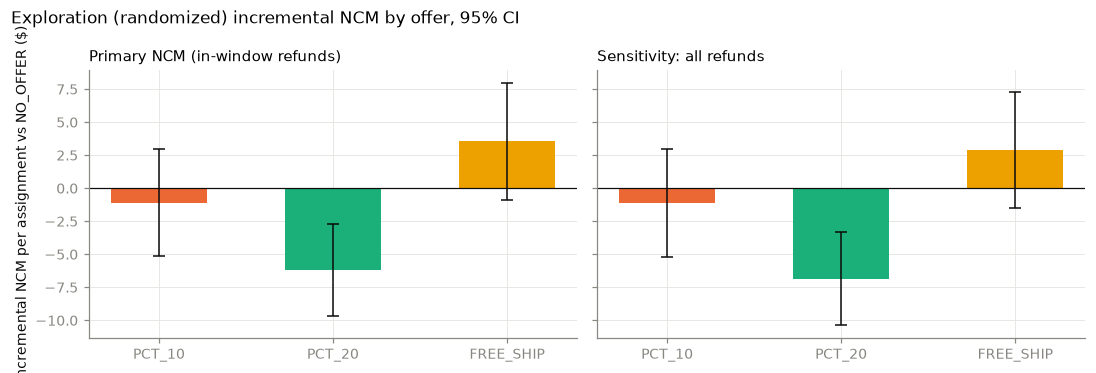

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.4), sharey=True)
for a, y, title in [(ax[0], "ncm_14d", "Primary NCM (in-window refunds)"), (ax[1], "ncm_14d_all_returns", "Sensitivity: all refunds")]:
    s = inc[inc.outcome == y]
    a.bar(s.offer_type, s.incremental_ncm, color=[COLORS[o] for o in s.offer_type], width=0.55)
    a.errorbar(s.offer_type, s.incremental_ncm, yerr=[s.incremental_ncm - s.ci_low, s.ci_high - s.incremental_ncm], fmt="none", ecolor=INK, capsize=4, lw=1)
    a.axhline(0, color=INK, lw=0.8); a.set_title(title, loc="left", fontsize=10)
ax[0].set_ylabel("Incremental NCM per assignment vs NO_OFFER ($)")
fig.suptitle("Exploration (randomized) incremental NCM by offer, 95% CI", x=0.01, ha="left", fontsize=11)
fig.tight_layout(); fig.savefig(FIGS / "04_incremental_ncm_by_offer.png", bbox_inches="tight"); plt.show()

## KPIs by campaign (stability over time)

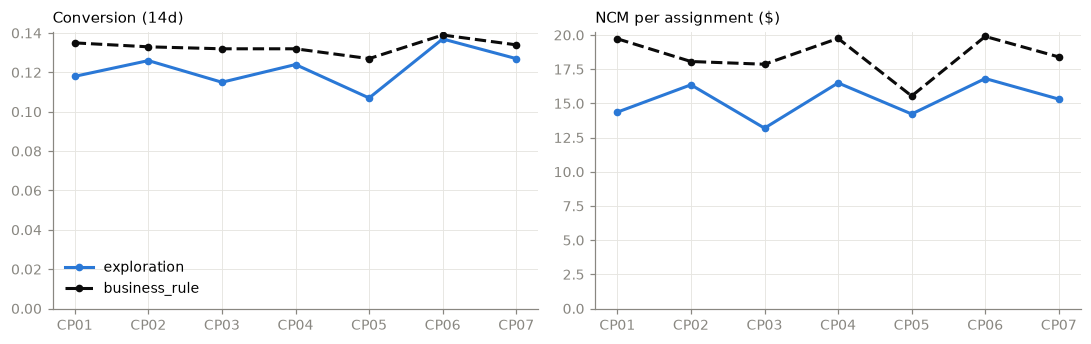

,assignments,conversion,aov,redemption_rate,promo_spend,promo_spend_per_assignment,ncm_total,ncm_per_assignment,ncm_all_returns_per_assignment
campaign_id,,,,,,,,,
CP01,1064,0.118,348.531,0.122,4174.36,3.923,15282.73,14.363,11.772
CP02,1110,0.126,348.231,0.124,4453.66,4.012,18161.92,16.362,13.081
CP03,1056,0.115,321.634,0.121,3212.89,3.043,13932.14,13.193,9.623
CP04,1117,0.124,357.015,0.133,4452.20,3.986,18430.39,16.500,11.093
CP05,1025,0.107,329.363,0.102,2063.40,2.013,14582.39,14.227,11.465
CP06,1095,0.137,342.408,0.139,3443.65,3.145,18419.40,16.821,13.824
CP07,1060,0.127,327.883,0.136,4121.67,3.888,16233.72,15.315,13.633


In [8]:
k_camp = kpis(df, ["campaign_id", "assignment_source"])
k_camp.to_csv(TABLES / "kpi_by_campaign.csv")
fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
for src, ls in [("exploration", "-"), ("business_rule", "--")]:
    s = k_camp.xs(src, level="assignment_source")
    ax[0].plot(s.index, s.conversion, ls, marker="o", ms=4, lw=2, color=INK if src == "business_rule" else "#2a78d6", label=src)
    ax[1].plot(s.index, s.ncm_per_assignment, ls, marker="o", ms=4, lw=2, color=INK if src == "business_rule" else "#2a78d6", label=src)
ax[0].set_title("Conversion (14d)", loc="left", fontsize=10); ax[1].set_title("NCM per assignment ($)", loc="left", fontsize=10)
ax[0].set_ylim(0, None); ax[1].set_ylim(0, None); ax[0].legend(frameon=False)
fig.tight_layout(); fig.savefig(FIGS / "04_kpi_by_campaign.png", bbox_inches="tight"); plt.show()
k_camp.xs("exploration", level="assignment_source")

## Segments — tenure / value proxy and behavioral intent
- **Tenure band:** `customer_tenure_days` <1y, 1–2y, 2y+.
- **Value band:** no completed order in prior 90d → `none`; otherwise `historical_ncm_90d` split at its median among 90d buyers (`low`/`high`).
- **Intent (behavioral):** `high` = ≥1 cart-add session in prior 30d; `medium` = any session in prior 30d without cart-add, or last session 31–90d ago; `low` = no session in prior 90d.

In [9]:
VALUE_CUT = df.loc[df.orders_90d > 0, "historical_ncm_90d"].median()
df["tenure_band"] = pd.cut(df.customer_tenure_days, [-1, 365, 730, np.inf], labels=["<1y", "1-2y", "2y+"])
df["value_band"] = np.select([df.orders_90d == 0, df.historical_ncm_90d < VALUE_CUT], ["none", "low"], "high")
df["intent"] = np.select([df.cart_add_sessions_30d > 0, (df.sessions_30d > 0) | (df.days_since_last_session <= 90)], ["high", "medium"], "low")
print(f"value cut (median 90d NCM among buyers) = ${VALUE_CUT:.2f}")
print(df[["tenure_band", "value_band", "intent"]].apply(lambda s: s.value_counts().to_dict()).to_dict())
exp = df[df.assignment_source == "exploration"]

value cut (median 90d NCM among buyers) = $102.90
{'tenure_band': {'2y+': 10729, '1-2y': 9316, '<1y': 6555}, 'value_band': {'none': 22900, 'low': 1850, 'high': 1850}, 'intent': {'low': 19867, 'medium': 5681, 'high': 1052}}


In [10]:
k_tv = kpis(df, ["tenure_band", "value_band"])
k_tv.to_csv(TABLES / "kpi_by_tenure_value.csv")
inc_seg = pd.concat([incremental(exp, "tenure_band").assign(dimension="tenure_band"), incremental(exp, "value_band").assign(dimension="value_band"),
                     incremental(exp, "intent").assign(dimension="intent"), incremental(exp, "is_member").assign(dimension="is_member")])
inc_seg.to_csv(TABLES / "incremental_ncm_by_segment_exploration.csv", index=False)
k_tv

assignments  conversion      aov  redemption_rate  promo_spend  promo_spend_per_assignment  ncm_total  ncm_per_assignment  ncm_all_returns_per_assignment
tenure_band value_band                                                                                                                                                           
<1y         high                411       0.204  373.055            0.198      1494.34                       3.636   11031.16              26.840                          17.496
            low                 453       0.177  292.058            0.164      1626.38                       3.590    8656.07              19.108                          14.731
            none               5691       0.122  359.952            0.109     14641.46                       2.573   96902.32              17.027                          13.910
1-2y        high                648       0.211  433.455            0.175      2223.87                       3.432   22471.52              34.678                          29.629
            low                 642       0.160  287.592            0.150      1288.03                       2.006   11835.24              18.435                          15.592
            none               8026       0.123  351.984            0.110     19842.55                       2.472  133001.28              16.571                          13.932
2y+         high                791       0.186  416.154            0.157      2716.58                       3.434   24347.84              30.781                          24.900
            low                 755       0.156  293.590            0.166      2684.28                       3.555   12526.92              16.592                          14.685
            none               9183       0.121  343.478            0.109     22835.00                       2.487  146235.16              15.925                          12.893

In [11]:
k_int = kpis(df, ["intent", "offer_type"])
k_int.to_csv(TABLES / "kpi_by_behavior_segment.csv")
k_mem = kpis(df, ["is_member", "offer_type"]); k_mem.to_csv(TABLES / "kpi_by_membership.csv")
k_int

assignments  conversion      aov  redemption_rate  promo_spend  promo_spend_per_assignment  ncm_total  ncm_per_assignment  ncm_all_returns_per_assignment
intent offer_type                                                                                                                                                           
high   FREE_SHIP           179       0.235  432.767            0.235        23.96                       0.134    7736.18              43.219                          39.155
       NO_OFFER            387       0.251  379.603              NaN         0.00                       0.000   15337.73              39.632                          37.773
       PCT_10              379       0.177  330.831            0.177      2458.90                       6.488    8066.12              21.283                          19.065
       PCT_20              107       0.150  261.108            0.150      1039.93                       9.719    1145.31              10.704                          10.433
low    FREE_SHIP          4457       0.107  451.989            0.107       173.71                       0.039   91127.47              20.446                          16.114
       NO_OFFER           4380       0.144  363.739              NaN         0.00                       0.000   94145.05              21.494                          18.795
       PCT_10             8084       0.102  294.732            0.102     26886.30                       3.326   84858.65              10.497                           8.427
       PCT_20             2946       0.106  290.487            0.106     22550.93                       7.655   24332.98               8.260                           5.059
medium FREE_SHIP          1131       0.171  443.908            0.171        71.88                       0.064   36329.70              32.122                          27.665
       NO_OFFER           1865       0.218  392.843              NaN         0.00                       0.000   67241.32              36.054                          30.856
       PCT_10             1977       0.149  289.842            0.149      9444.19                       4.777   29787.40              15.067                          11.548
       PCT_20              708       0.140  271.297            0.140      6702.69                       9.467    6899.60               9.745                           6.253

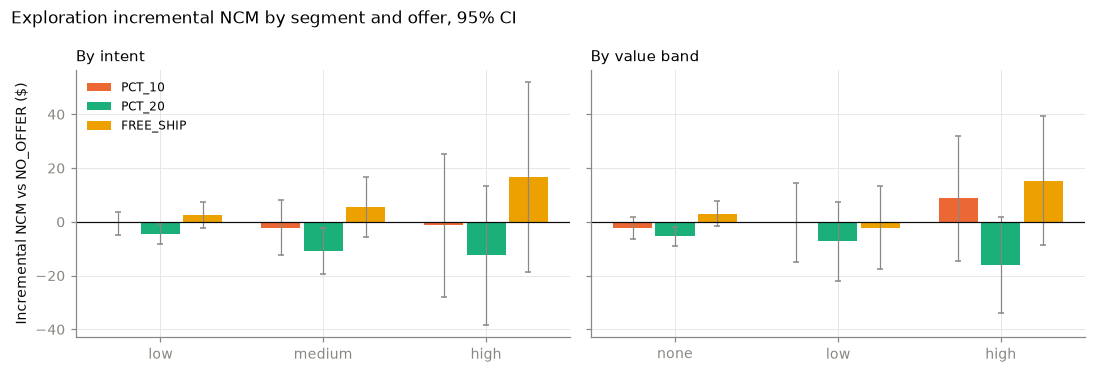

offer_type           FREE_SHIP  PCT_10  PCT_20
dimension   segment                           
intent      high         16.53   -1.34  -12.48
            low           2.57   -0.58   -4.55
            medium        5.57   -2.18  -10.86
is_member   0             6.31    0.26   -5.48
            1            -3.38   -4.44   -7.80
tenure_band 1-2y          5.12   -1.82   -4.98
            2y+           1.62   -3.94   -8.24
            <1y           4.72    4.85   -4.19
value_band  high         15.37    8.77  -15.97
            low          -2.09   -0.38   -7.21
            none          3.03   -2.23   -5.33

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.4), sharey=True)
for a, dim in [(ax[0], "intent"), (ax[1], "value_band")]:
    s = inc_seg[(inc_seg.dimension == dim) & (inc_seg.outcome == "ncm_14d")]
    segs = {"intent": ["low", "medium", "high"], "value_band": ["none", "low", "high"]}[dim]
    x = np.arange(len(segs))
    for j, o in enumerate(OFFERS[1:]):
        v = s[s.offer_type == o].set_index("segment").reindex(segs)
        a.bar(x + (j - 1) * 0.26, v.incremental_ncm, 0.24, color=COLORS[o], label=o)
        a.errorbar(x + (j - 1) * 0.26, v.incremental_ncm, yerr=[v.incremental_ncm - v.ci_low, v.ci_high - v.incremental_ncm], fmt="none", ecolor=MUTED, lw=0.8, capsize=2)
    a.set_xticks(x, segs); a.axhline(0, color=INK, lw=0.8); a.set_title(f"By {dim.replace('_', ' ')}", loc="left", fontsize=10)
ax[0].set_ylabel("Incremental NCM vs NO_OFFER ($)"); ax[0].legend(frameon=False, fontsize=8)
fig.suptitle("Exploration incremental NCM by segment and offer, 95% CI", x=0.01, ha="left", fontsize=11)
fig.tight_layout(); fig.savefig(FIGS / "04_incremental_ncm_by_segment.png", bbox_inches="tight"); plt.show()
inc_seg[inc_seg.outcome == "ncm_14d"].pivot_table(index=["dimension", "segment"], columns="offer_type", values="incremental_ncm").round(2)

## Key descriptive findings
Printed from the tables above; interpret exploration-based increments as causal estimates for the historical population only,
and business_rule comparisons as descriptive (targeted assignment).

In [13]:
e = inc[inc.outcome == "ncm_14d"].set_index("offer_type")
ea = inc[inc.outcome == "ncm_14d_all_returns"].set_index("offer_type")
print(f"Overall conversion {overall.conversion.iloc[0]:.1%}, AOV ${overall.aov.iloc[0]:.0f}, NCM/assignment ${overall.ncm_per_assignment.iloc[0]:.2f}, total promo spend ${overall.promo_spend.iloc[0]:,.0f}")
for o in OFFERS[1:]:
    print(f"{o:9s} exploration Δconv {e.loc[o, 'incremental_conversion']:+.3f} | ΔNCM ${e.loc[o, 'incremental_ncm']:+.2f} "
          f"[{e.loc[o, 'ci_low']:+.2f}, {e.loc[o, 'ci_high']:+.2f}] | all-refunds ΔNCM ${ea.loc[o, 'incremental_ncm']:+.2f}")

Overall conversion 13.0%, AOV $352, NCM/assignment $17.56, total promo spend $69,352
PCT_10    exploration Δconv +0.008 | ΔNCM $-1.08 [-5.12, +2.96] | all-refunds ΔNCM $-1.11
PCT_20    exploration Δconv +0.011 | ΔNCM $-6.17 [-9.65, -2.70] | all-refunds ΔNCM $-6.85
FREE_SHIP exploration Δconv +0.018 | ΔNCM $+3.56 [-0.89, +8.01] | all-refunds ΔNCM $+2.87
